In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

Predictions:
- Part A (H, CNOT): 00 and 11 dominate, about 50/50 each. 01 and 10 should not appear.
- Part B (H, CNOT, X on qubit 1): 01 and 10 dominate, about 50/50 each. 00 and 11 should not appear.
- Not all four outcomes appear. Entanglement links the two qubits, so only two outcomes are possible in each circuit.

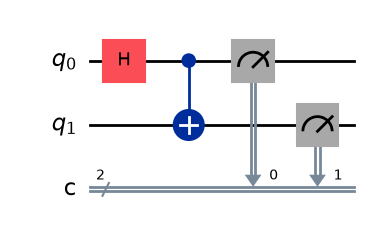

In [2]:
qc_a = QuantumCircuit(2, 2)
qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure([0, 1], [0, 1])
qc_a.draw("mpl")

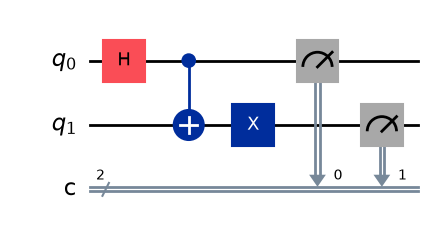

In [3]:
qc_b = QuantumCircuit(2, 2)
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)
qc_b.measure([0, 1], [0, 1])
qc_b.draw("mpl")

In [4]:
sim = AerSimulator()
counts_a = sim.run(qc_a, shots=100).result().get_counts()
counts_b = sim.run(qc_b, shots=100).result().get_counts()
print("Part A:", counts_a)
print("Part B:", counts_b)

Part A: {'11': 53, '00': 47}
Part B: {'01': 42, '10': 58}


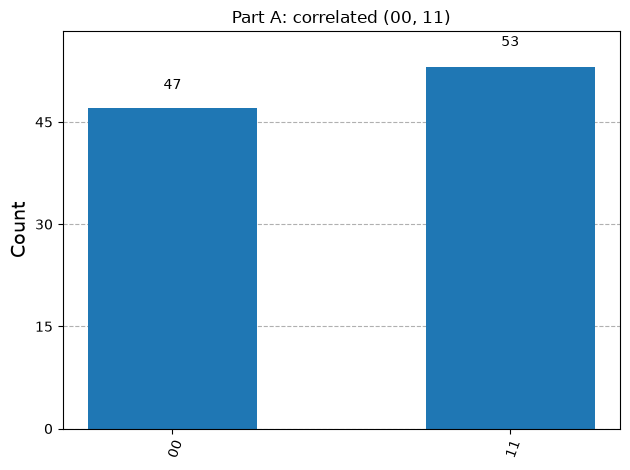

In [5]:
plot_histogram(counts_a, title="Part A: correlated (00, 11)")

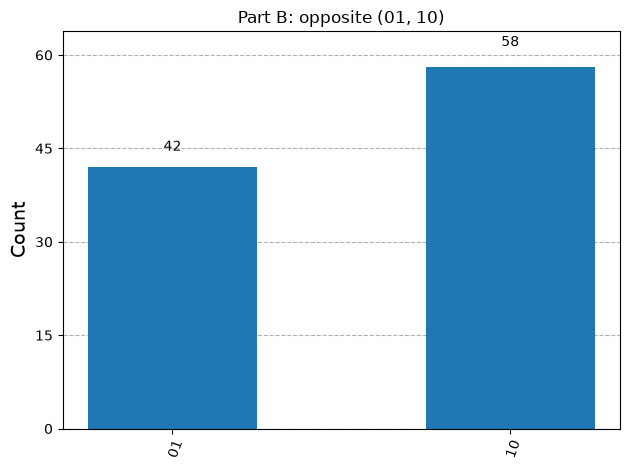

In [6]:
plot_histogram(counts_b, title="Part B: opposite (01, 10)")

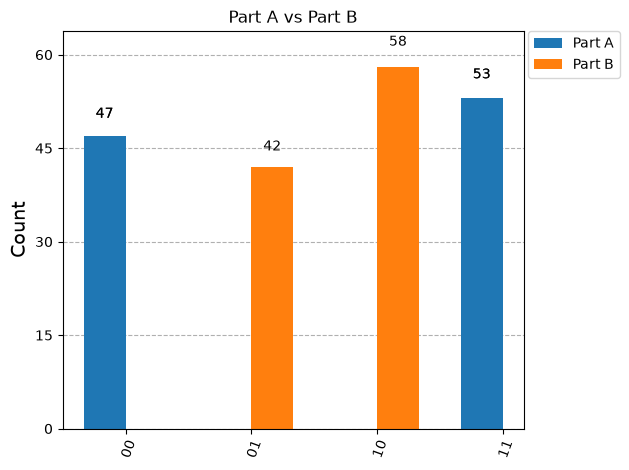

In [8]:
plot_histogram([counts_a, counts_b], legend=["Part A", "Part B"], title="Part A vs Part B")

## Comparison and Explanation

- **Part A (H, CNOT):** Predicted `00` and `11`. Actual: `{'00': 47, '11': 53}`. Matches.
- **Part B (H, CNOT, X on qubit 1):** Predicted `01` and `10`. Actual: `{'01': 42, '10': 58}`. Matches.
**Which outcomes dominate in Part A?** `00` and `11`. The two qubits always give the same result.

**Which outcomes dominate in Part B?** `01` and `10`. The two qubits always give opposite results.

**What changed?** One X gate was added on qubit 1 after the CNOT.

**Why did the relationship change?** The H gate puts qubit 0 in superposition and the CNOT entangles the qubits, giving (|00⟩ + |11⟩)/√2. The X gate flips qubit 1 only, turning |00⟩ into |01⟩ and |11⟩ into |10⟩. The state becomes (|01⟩ + |10⟩)/√2, so the qubits are still entangled, but now they always differ.

**Why not all four outcomes?** Entanglement ties qubit 1 to qubit 0, so only two of the four outcomes are possible. Counts are not exactly 50/50 because only 100 shots were used.